# CAMP on a public brain MRI set

This notebook trains CAMP on one public brain-MRI collection and then generates new slices. It uses the Python API: import `CAMP`, train the segmentor, train the recommender, and generate.

The slices are already arranged under `data/brain`. Tumour slices and their masks sit in `data/brain/brain`. Tumour-free backgrounds sit in `data/brain/normal`, as image files in that folder. CAMP reads that layout. The dataset stays on your machine. `data/` and `weights/` are gitignored.

The dataset card (title, URL, and licence) is not in this notebook yet. Add it here when you have the Kaggle page.

This example runs for dozens of epochs, in both training stages, so the figures are a real fit:

- Segmentor: 40 epochs, the first 15 with the encoder frozen, 512 px, patch 128, batch 8.
- Recommender: 30 epochs, then 10 more at a lower learning rate, batch 4.
- Generate: 4 images, seed 42, with the scale, rotation, and flip search on. Two of them are drawn in full.

The paper defaults are 80 segmentor epochs and 60 recommender epochs plus 20 of fine-tuning, in [`configs/default.yaml`](../../configs/default.yaml). The numbers above are the ones in [`configs/brain.yaml`](../../configs/brain.yaml):

```bash
python -m camp train segmentor --config configs/brain.yaml
python -m camp train recommender --config configs/brain.yaml
python -m camp generate --config configs/brain.yaml
```

The CLI writes a debug strip for every generated image, up to five. This notebook draws two of the four with `plot_generate_trace`.

Early stopping can end a stage before the last epoch. The segmentor cell prints the epoch saved in the checkpoint. Improving recommender epochs are marked `best` in the log.

Re-running this file needs `jupyter` and `ipykernel` inside the environment you use for CAMP. They are not part of `environment.yml`. The notebook looks upward from the working directory until it finds the repository. If the kernel starts outside the repository, set `CAMP_ROOT` to the repository path. The training log is the epoch lines only, with paths relative to the repository. Progress bars stay off.


In [1]:
from pathlib import Path
import os

def repo_root():
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "camp" / "__init__.py").is_file():
            return folder
    raise RuntimeError("Open this notebook from the CAMP repository.")


ROOT = repo_root()
os.chdir(ROOT)

from camp import CAMP

camp = CAMP(root=ROOT, device="cuda")
print("device", camp.device.type)

# One line per epoch, and paths relative to the repository.
import io
import logging
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import tqdm.auto as tqdm_auto
from IPython.display import Image, Markdown, display

os.environ["TQDM_DISABLE"] = "1"
_tqdm = tqdm_auto.tqdm


def _quiet_bar(*args, **kwargs):
    kwargs["disable"] = True
    return _tqdm(*args, **kwargs)


tqdm_auto.tqdm = _quiet_bar
warnings.filterwarnings("ignore", message=r"Conversion from CIE-LAB")


def scrub(text):
    text = str(text).replace("\\", "/")
    root = str(ROOT).replace("\\", "/")
    return text.replace(root + "/", "").replace(root, "")


class _RelativePaths(logging.Filter):
    def filter(self, record):
        message = scrub(record.getMessage())
        record.msg = message
        record.args = ()
        return not message.startswith("Wrote ")


logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
logging.getLogger("camp").setLevel(logging.INFO)
logging.getLogger("camp").addFilter(_RelativePaths())


def show_png(path):
    path = Path(path)
    display(Markdown("`%s`" % path.name))
    display(Image(filename=str(path)))


def show_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


device cuda


## Data

`class_dirs` resolves the source (slices the instance is copied from) and the target (slices it is pasted onto). Here the source is `data/brain/brain`, with `images/` and `masks/` side by side. A mask shares the image stem, and a `.jpg` pairs with a `.png`. The target is `data/brain/normal`. Those backgrounds have no nested `images/` folder, which CAMP accepts: it reads the image files in the folder itself.

The two rows are source slices and the masks that mark the tumour. The last image is one tumour-free background.


source  500 paired  data/brain/brain
target  501 images  data/brain/normal


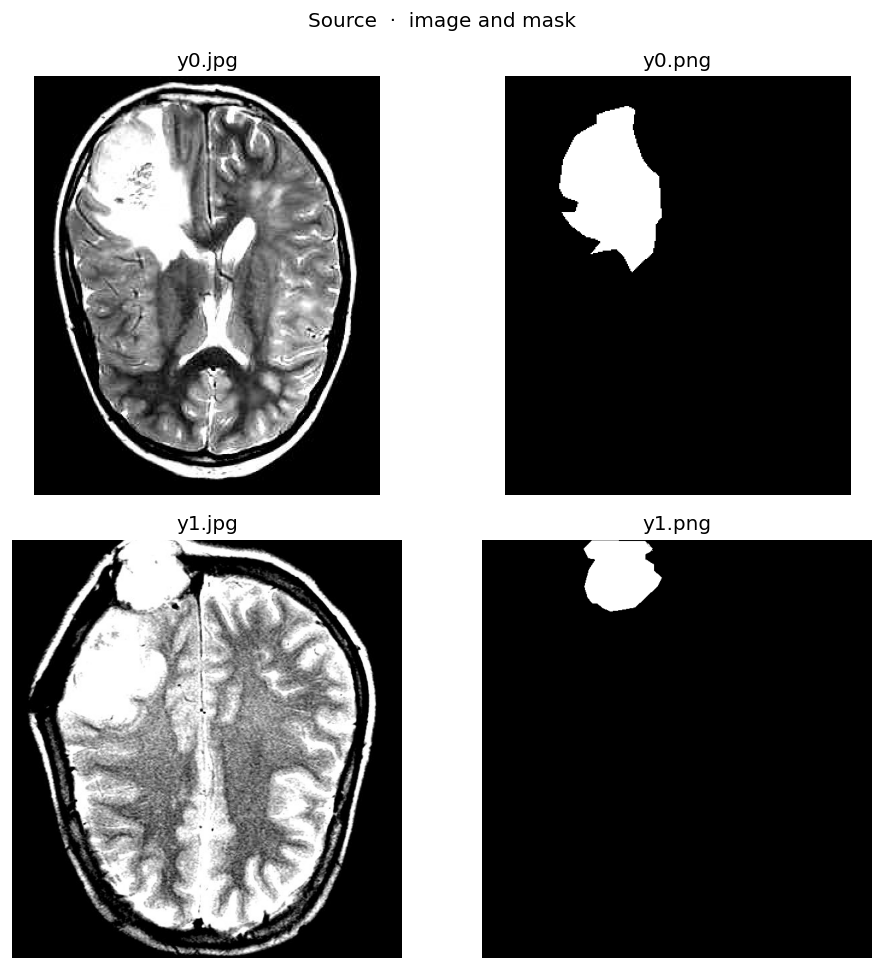

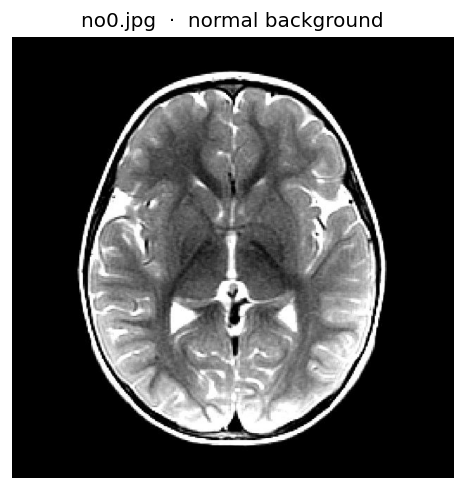

In [2]:
from PIL import Image as PILImage
import numpy as np
from camp.io import class_dirs

source_dir, target_dir = class_dirs(ROOT, "brain")
image_dir = source_dir / "images"
mask_dir = source_dir / "masks"
paired = sorted(
    path for path in image_dir.glob("*.jpg")
    if (mask_dir / (path.stem + ".png")).is_file()
)
normals = [
    path for path in sorted(target_dir.iterdir())
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
]
print("source  %d paired  %s" % (len(paired), scrub(source_dir)))
print("target  %d images  %s" % (len(normals), scrub(target_dir)))

shown = paired[:2]
fig, axes = plt.subplots(len(shown), 2, figsize=(8.2, 4.1 * len(shown)))
for row, path in enumerate(shown):
    mask_path = mask_dir / (path.stem + ".png")
    axes[row, 0].imshow(np.array(PILImage.open(path).convert("RGB")))
    axes[row, 0].set_title(path.name)
    axes[row, 1].imshow(np.array(PILImage.open(mask_path).convert("L")), cmap="gray")
    axes[row, 1].set_title(mask_path.name)
    for axis in axes[row]:
        axis.set_axis_off()
fig.suptitle("Source  ·  image and mask")
fig.tight_layout()
show_figure(fig)

fig, axis = plt.subplots(figsize=(4.2, 4.2))
axis.imshow(np.array(PILImage.open(normals[0]).convert("RGB")))
axis.set_title("%s  ·  normal background" % normals[0].name)
axis.set_axis_off()
fig.tight_layout()
show_figure(fig)


## 1. Segmentor

The segmentor is a UNet++ with an ImageNet encoder. It learns a binary mask of the instance. The first 15 epochs train the decoder with the encoder frozen. The remaining epochs unfreeze the encoder. `debug=True` writes the same eight validation figures as `python -m camp train segmentor --debug`, under `weights/brain/segmentor/debug/`.

The checkpoint keeps the epoch with the best validation Dice. That epoch is printed after the log. The overview sorts the eight validation slices by Dice, worst at the top. The close-up is the strongest of those eight that still has a tumour ring in the target. A slice with an empty target and an empty prediction scores Dice 1 and stays in the overview. The close-up shows the probability, the contours, and the error map.


In [3]:
import torch

segmentor_ckpt = camp.train_segmentor(
    "brain",
    epochs=40,
    freeze_epochs=15,
    debug=True,
)
state = torch.load(segmentor_ckpt, map_location="cpu")
print(
    "best checkpoint  epoch %d / %d  val dice %.4f"
    % (int(state["epoch"]) + 1, 40, float(state["val_dice"]))
)


segmentor  brain
  data     400 train / 100 val  data/brain/brain
  setup    efficientnet-b3  512 px  batch 8
  phase 1  15 epochs  decoder  lr 3.0e-04
  phase 2  25 epochs  encoder  lr 1.0e-04
  output   weights/brain/segmentor
  debug    8 validation figures
1/40  phase 1  train loss 0.9493 dice 0.0839  val loss 0.9442 dice 0.1044  iou 0.0554  lr 3.8e-05  best
2/40  phase 1  train loss 0.9418 dice 0.1214  val loss 0.9338 dice 0.1654  iou 0.0910  lr 6.3e-05  best
3/40  phase 1  train loss 0.9176 dice 0.2621  val loss 0.8790 dice 0.4042  iou 0.2589  lr 1.0e-04  best
4/40  phase 1  train loss 0.8666 dice 0.4224  val loss 0.8369 dice 0.4818  iou 0.3282  lr 1.5e-04  best
5/40  phase 1  train loss 0.8080 dice 0.5141  val loss 0.7801 dice 0.5400  iou 0.3843  lr 2.0e-04  best
6/40  phase 1  train loss 0.7315 dice 0.5773  val loss 0.6900 dice 0.6092  iou 0.4606  lr 2.4e-04  best
7/40  phase 1  train loss 0.6438 dice 0.6122  val loss 0.6276 dice 0.6303  iou 0.4845  lr 2.8e-04  best
8/40  phase

segmentor
checkpoint  loaded  weights/brain/segmentor/best.pth
selection  8 of 100 validation images, spread by Dice, worst at the top

00  worst    dice 0.000  iou 0.000  precision 0.000  recall 0.000  y31.jpg
01  low      dice 0.529  iou 0.360  precision 0.779  recall 0.401  y35.jpg
02  low      dice 0.724  iou 0.567  precision 0.697  recall 0.752  y111.jpg
03  low      dice 0.805  iou 0.674  precision 0.850  recall 0.764  y37.jpg
04  high     dice 0.865  iou 0.762  precision 0.835  recall 0.897  y293.jpg
05  high     dice 0.879  iou 0.785  precision 0.917  recall 0.845  y13.jpg
06  high     dice 0.903  iou 0.824  precision 0.917  recall 0.890  y471.jpg
07  best     dice 1.000  iou 1.000  precision 1.000  recall 1.000  y257.jpg


`seg_overview.png`

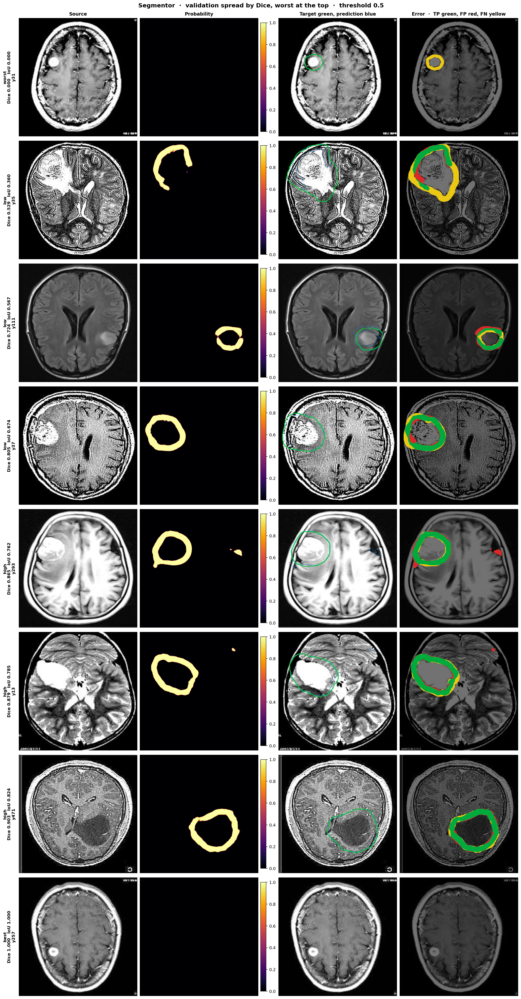

`seg_06_high.png`

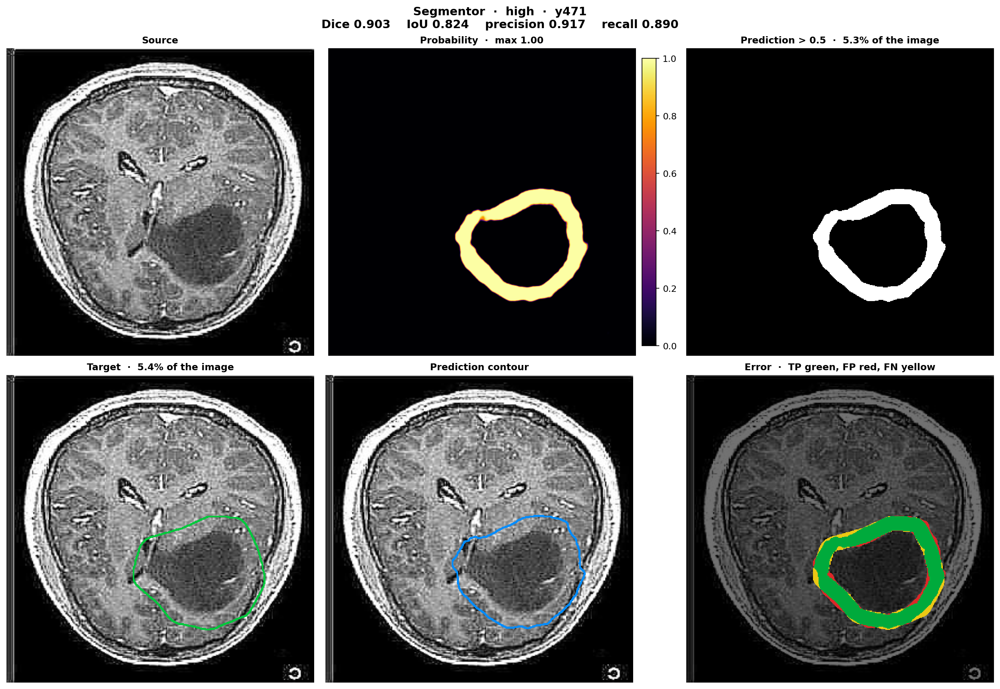

In [4]:
seg_dir = ROOT / "weights" / "brain" / "segmentor" / "debug"
print(scrub((seg_dir / "index.txt").read_text(encoding="utf-8")).rstrip())
show_png(seg_dir / "seg_overview.png")
show_png(seg_dir / "seg_06_high.png")


## 2. Recommender

The recommender freezes the segmentor and attends from the tissue around the instance onto the target slice. The output is a placement heatmap. It trains for 30 epochs, then for 10 more at a lower learning rate. `debug=True` writes eight validation heatmaps under `weights/brain/recommender/debug/`, ordered by heatmap error, worst at the top.

Improving epochs are marked `best` in the log. The two figures are the weakest of the eight and the best.


In [5]:
camp.train_recommender(
    "brain",
    epochs=30,
    finetune_epochs=10,
    debug=True,
)


recommender  brain
  data     400 train / 100 val  data/brain/brain
  setup    512 px  batch 4
  backbone weights/brain/segmentor/best.pth
  phase 1  30 epochs  lr 3.0e-04
  phase 2  10 epochs  lr 5.0e-05
  output   weights/brain/recommender
  debug    8 validation figures
1/30  phase 1  train 0.5340  val 0.3964  lr 3.0e-04  best
2/30  phase 1  train 0.4976  val 0.4095  lr 3.0e-04
3/30  phase 1  train 0.4950  val 0.3238  lr 3.0e-04  best
4/30  phase 1  train 0.4749  val 0.3230  lr 3.0e-04  best
5/30  phase 1  train 0.5150  val 0.4151  lr 3.0e-04
6/30  phase 1  train 0.5113  val 0.3804  lr 3.0e-04
7/30  phase 1  train 0.4787  val 0.4336  lr 3.0e-04
8/30  phase 1  train 0.4822  val 0.4056  lr 3.0e-04
9/30  phase 1  train 0.4965  val 0.4000  lr 3.0e-04
10/30  phase 1  train 0.4492  val 0.3868  lr 3.0e-04
11/30  phase 1  train 0.4588  val 0.3330  lr 3.0e-04
12/30  phase 1  train 0.4412  val 0.3610  lr 3.0e-04
13/30  phase 1  train 0.4736  val 0.4000  lr 3.0e-04
14/30  phase 1  train 0.4367

recommender
checkpoint  loaded  weights/brain/recommender/best.pth
selection  8 of 99 validation images, spread by heatmap MSE, worst at the top
boxes  window mean, stride patch/4, NMS IoU 0.3

00  worst    mse 0.0873  peak_in 0.722  peak_out 0.842  patch 1/1  y195.jpg
01  low      mse 0.0621  peak_in 0.739  peak_out 0.735  patch 1/1  y253.jpg
02  low      mse 0.0502  peak_in 0.658  peak_out 0.805  patch 1/1  y480.jpg
03  low      mse 0.0438  peak_in 0.753  peak_out 0.694  patch 1/1  y199.jpg
04  high     mse 0.0387  peak_in 0.725  peak_out 0.697  patch 1/1  y37.jpg
05  high     mse 0.0331  peak_in 0.762  peak_out 0.829  patch 1/1  y352.jpg
06  high     mse 0.0271  peak_in 0.704  peak_out 0.708  patch 1/1  y11.jpg
07  best     mse 0.0185  peak_in 0.752  peak_out 0.704  patch 1/1  y357.jpg


`rec_00_worst.png`

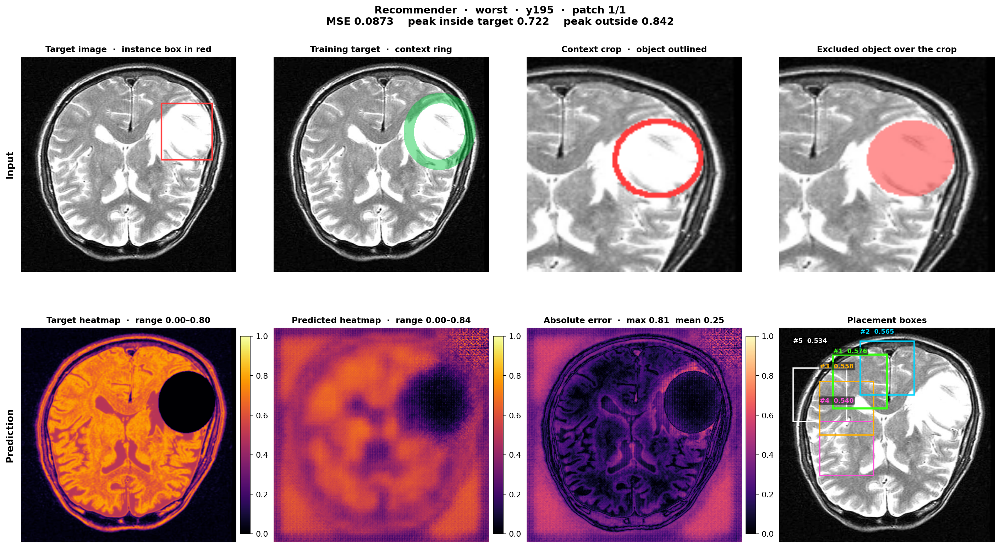

`rec_07_best.png`

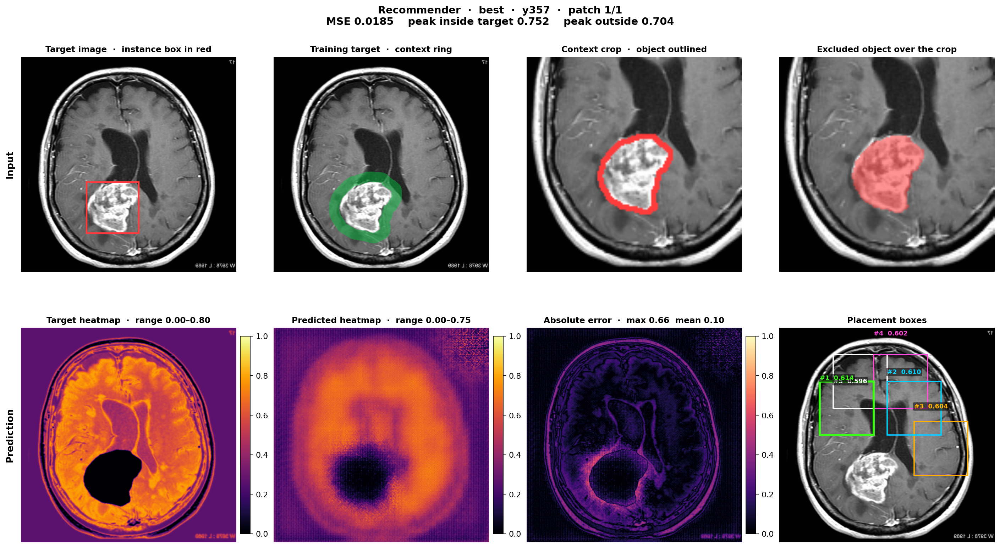

In [6]:
rec_dir = ROOT / "weights" / "brain" / "recommender" / "debug"
print(scrub((rec_dir / "index.txt").read_text(encoding="utf-8")).rstrip())
show_png(rec_dir / "rec_00_worst.png")
show_png(rec_dir / "rec_07_best.png")


## 3. Generate

`load` reads both checkpoints. Each sample copies one tumour instance onto a normal background: the segmentor (or the given mask) cuts the instance, the recommender scores where it belongs, and the blend paints it in. `use_tto=True` searches scale, rotation, and flip before that paste.

`debug_n=2` keeps the full trace on the first two samples. `plot_generate_trace` draws the segmentation, the heatmap and boxes, and the paste. The four images and masks are written to `data/augmented/brain/` on the machine that runs the notebook. The two strips in `examples/brain/outputs/` are the ones included in the repository.


loaded  brain  cuda
sources 50
targets 50
patches  50
1/4  score 0.6263  scale 0.9  rot 0  flip off
2/4  score 0.5984  scale 0.9  rot 0  flip off
3/4  score 0.6147  scale 0.9  rot 90  flip off
4/4  score 0.6189  scale 0.9  rot 0  flip off
samples 4
strips 2


`generate_00.png`

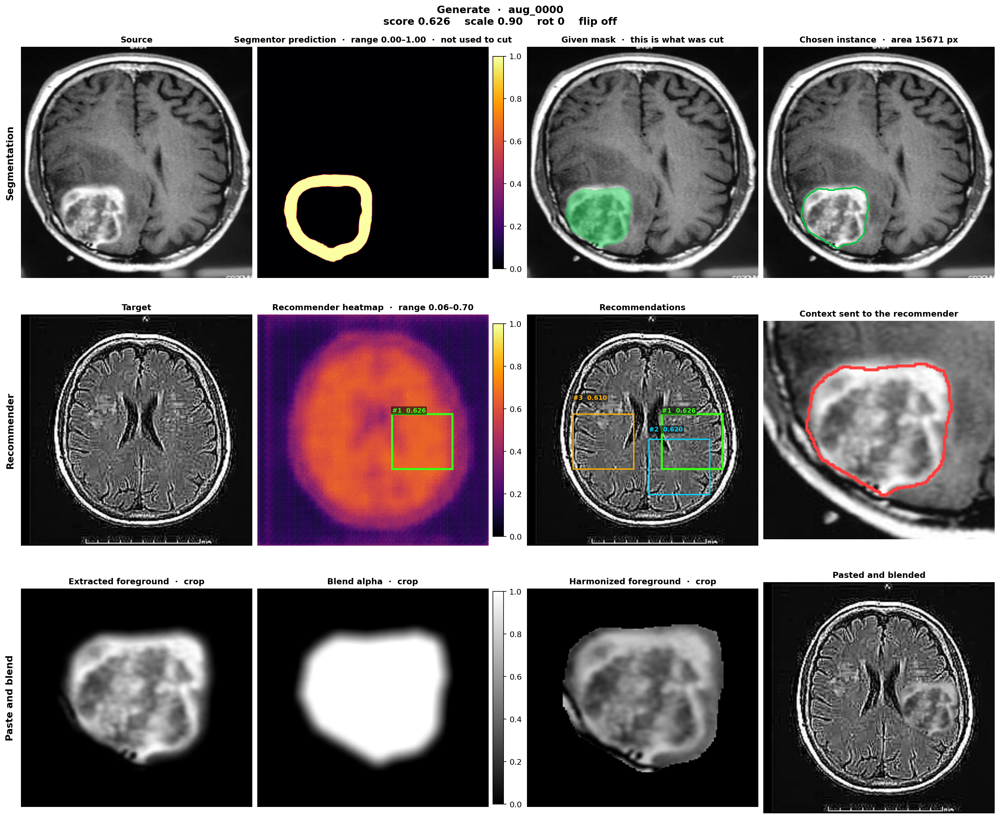

`generate_01.png`

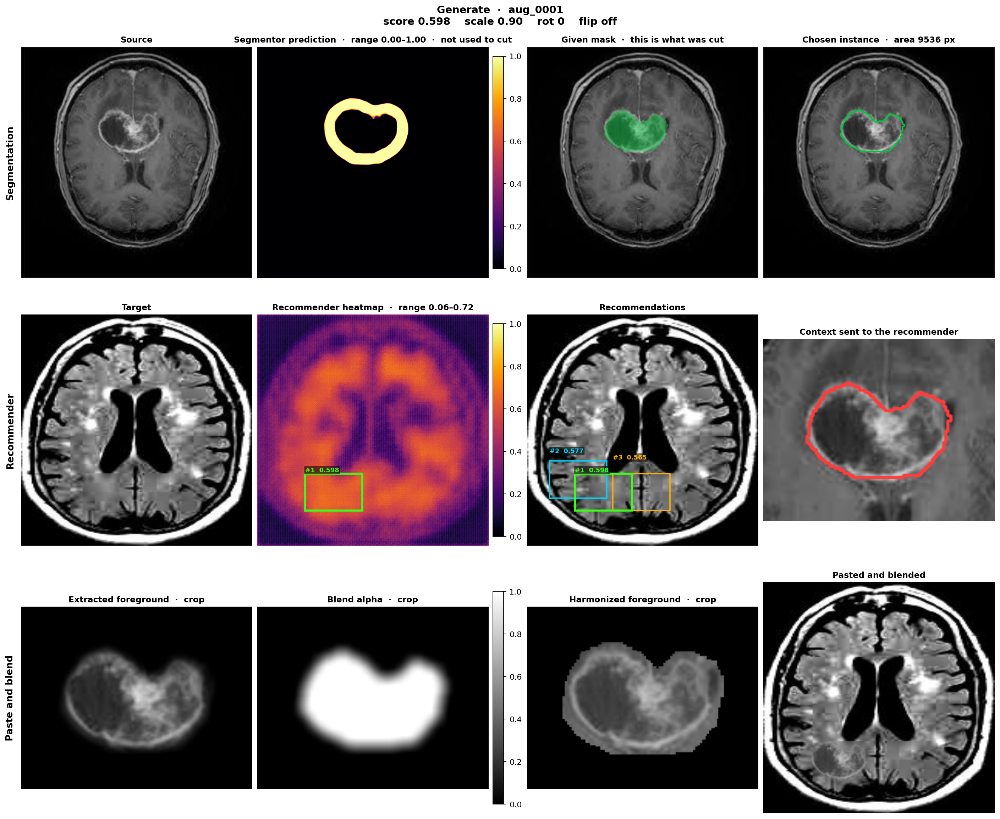

In [7]:
from camp.figures import plot_generate_trace
from camp.io import class_dirs, load_image_mask_pairs, load_images

source_dir, target_dir = class_dirs(ROOT, "brain")
sources, masks = load_image_mask_pairs(source_dir, max_images=50)
targets = load_images(target_dir, max_images=50)
camp.load("brain")
print("sources %d" % len(sources))
print("targets %d" % len(targets))

samples = camp.generate_batch(
    targets,
    sources,
    masks=masks,
    n=4,
    out="data/augmented/brain",
    use_tto=True,
    seed=42,
    debug_n=2,
)
print("samples %d" % len(samples))

gallery = ROOT / "examples" / "brain" / "outputs"
shown = 0
for sample in samples:
    if not getattr(sample, "debug", None):
        continue
    fig = plot_generate_trace(sample.debug)
    fig.savefig(
        gallery / ("generate_%02d.png" % shown),
        dpi=160,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.close(fig)
    shown += 1
print("strips %d" % shown)
for index in range(shown):
    show_png(gallery / ("generate_%02d.png" % index))


## Where the files are

This repository includes the figures in `examples/brain/outputs`: the overview, one segmentation detail, two heatmaps, and two generate strips.

Running the notebook also writes the checkpoints and the generated images on your machine. `data/` and `weights/` are gitignored, so those files are not part of the repository.

| Path | Written locally when you run the notebook |
| --- | --- |
| `weights/brain/segmentor/best.pth` | Segmentor checkpoint. |
| `weights/brain/recommender/best.pth` | Recommender checkpoint. |
| `weights/brain/*/debug/` | The eight validation figures from `debug=True`. |
| `data/augmented/brain/` | The four generated images and masks. |
